In [ ]:
import networkx as nx
import pandas as pd
import numpy as np
import statistics
import random
import json

import matplotlib.pyplot as plt

from collections import Counter

In [ ]:
archivo_entrada = "wiki-talk-temporal.txt"
archivo_salida = "wiki-talk-temporal.graphml"

DG = nx.DiGraph()
self_loops = 0
with open(archivo_entrada, "r") as f:
    for linea in f:
        # Ignorar comentarios y líneas vacías
        if linea.startswith("#") or not linea.strip():
            continue

        partes = linea.split()

        origen = int(partes[0])
        destino = int(partes[1])
        timestamp = int(partes[2])

        # eliminamos los ciclos
        if origen == destino:
            self_loops += 1
            continue

        # Si la relación ya existe, incrementamos el número de interacciones
        if DG.has_edge(origen, destino):
            DG[origen][destino]["weight"] += 1

            # Actualizar última interacción
            if timestamp > DG[origen][destino]["last_timestamp"]:
                DG[origen][destino]["last_timestamp"] = timestamp
            # Actualizar primera interacción
            if timestamp < DG[origen][destino]["first_timestamp"]:
                DG[origen][destino]["first_timestamp"] = timestamp

        else:
            DG.add_edge(origen, destino, weight=1,
                first_timestamp=timestamp,
                last_timestamp=timestamp
            )

nx.write_graphml(DG, archivo_salida)
print("Self-loops eliminados:", self_loops)
print("Archivo generado:", archivo_salida)

Self-loops eliminados: 1732602
Archivo generado: wiki-talk-temporal.graphml


In [ ]:
def degrees_list(G):
    return [d_v for (v, d_v) in G.degree()]

def AnalyzeGraph(G, verbose=True):
    print("Analyzing the graph.")
    print(f'There are {G.number_of_nodes()} nodes: {G.nodes() if verbose else "--"}')
    print(f'There are {G.number_of_edges()} edges: {G.edges() if verbose else "--"}')
    print(f'Average degree: {statistics.mean(degrees_list(G))}')
    print(f'Density: {nx.density(G)}')

In [ ]:
AnalyzeGraph(DG, verbose=False)

Analyzing the graph.
There are 1094018 nodes: --
There are 3130742 edges: --
Average degree: 5.72338297907347
Density: 2.6157651019469853e-06


### Tarefas

Tareas

1. Calcular o número de vértices e de arestas, o grau médio dos vértices.
2. Calcular corretamente os coeficientes de clusterização global (ambos).
3. Calcular o coeficiente de clusterização de cada nó e plotar a sua distribuição.
4. Calcular a distância média entre os vértices.
5. Calcular o diâmetro do grafo.
6. Calcular a densidade.
7. Calcular e plotar a distribuição dos graus dos nós.
8. Calcular o número de componentes do grafo (no caso dos grafos não direcionados) e, se tiver mais de uma componente, plotar a distribuição dos tamanhos das componentes.
9. De forma complementar e opcional, fazer uma visualização do grafo (pode ser entregue em arquivo separado).

#### Parte 1

In [ ]:
# 1. Calcular o número de vértices e de arestas, o grau médio dos vértices.
n = DG.number_of_nodes()
m = DG.number_of_edges()

average_degree = sum(dict(DG.degree()).values()) / n
average_in_degree = sum(dict(DG.in_degree()).values()) / n
average_out_degree = sum(dict(DG.out_degree()).values()) / n

print("Número de vértices:", n)
print("Número de aristas:", m)
print("Grado medio:", average_degree)
print("Grado medio de entrada:", average_in_degree)
print("Grado medio de salida:", average_out_degree)

Número de vértices: 1094018
Número de aristas: 3130742
Grado medio: 5.72338297907347
Grado medio de entrada: 2.861691489536735
Grado medio de salida: 2.861691489536735


#### Parte 2

In [ ]:
# 2. Calcular corretamente os coeficientes de clusterização global (ambos).
G = DG.to_undirected()

print("Dirigido:", G.is_directed())
print("Vértices:", G.number_of_nodes())
print("Aristas:", G.number_of_edges())

Dirigido: False
Vértices: 1094018
Aristas: 2787967


In [ ]:
grados = dict(G.degree())
triangulos = nx.triangles(G)

# 2.1. Clustering medio
clustering = {}
for nodo in G.nodes():
    k = grados[nodo]
    if k < 2:
        clustering[nodo] = 0
    else:
        clustering[nodo] = (2 * triangulos[nodo]) / (k * (k - 1))

C_medio = sum(clustering.values()) / G.number_of_nodes()
print("Clustering medio:", C_medio)

# 2.2. Transitividad
total_triangulos = sum(triangulos.values()) / 3
total_triplas = sum(k * (k - 1) / 2 for k in grados.values())

C_global = (3 * total_triangulos / total_triplas)
print("Transitividad:", C_global)

Clustering medio: 0.10260704970463057
Transitividad: 0.0014683934833112412


#### Parte 3

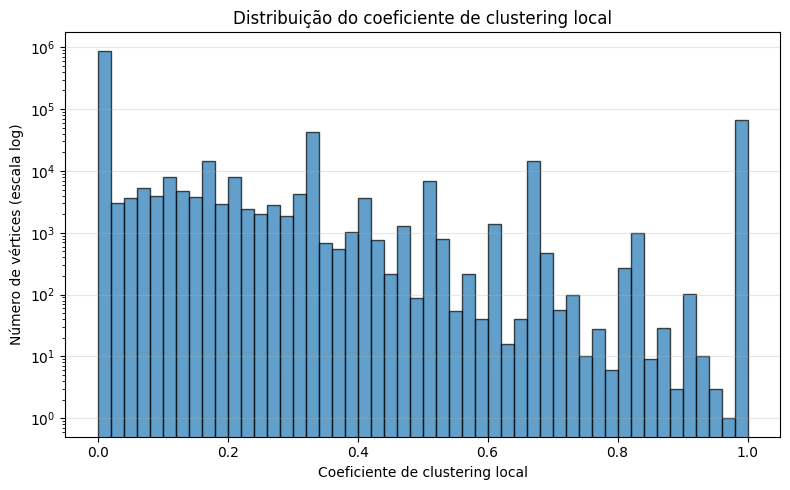

In [ ]:
# 3. Calcular o coeficiente de clusterização de cada nó e plotar a sua distribuição.
valores_clustering = list(clustering.values())

plt.figure(figsize=(8, 5))
plt.hist(
    valores_clustering,
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.yscale("log")
plt.xlabel("Coeficiente de clustering local")
plt.ylabel("Número de vértices (escala log)")
plt.title("Distribuição do coeficiente de clustering local")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Parte 4

In [ ]:
#4. Calcular a distância média entre os vértices.
print("Grafo conexo:", nx.is_connected(G))

Grafo conexo: False


In [ ]:
maior_componente = max(nx.connected_components(G), key=len)
G_gigante = G.subgraph(maior_componente)

print("Vértices de G:", G.number_of_nodes())
print("Vértices de la componente gigante:", G_gigante.number_of_nodes())

porcentaje = (
    G_gigante.number_of_nodes()
    / G.number_of_nodes()
    * 100
)
print(f"Porcentaje de nodos: {porcentaje:.2f}%")

Vértices de G: 1094018
Vértices de la componente gigante: 1091742
Porcentaje de nodos: 99.79%


In [ ]:
# nx.average_shortest_path_length(G_gigante)

In [ ]:
random.seed(42)
num_amostras = 100
nos_amostra = random.sample(list(G_gigante.nodes()), num_amostras)
distancias_medias = []

for i, nodo in enumerate(nos_amostra):
    distancias = nx.single_source_shortest_path_length(G_gigante, nodo)

    # No contamos distancia del nodo consigo mismo
    valores = [
        d for destino, d in distancias.items()
        if destino != nodo
    ]

    distancias_medias.append(sum(valores) / len(valores))
    if (i + 1) % 10 == 0:
        print(f"{i + 1}/{num_amostras} nodos procesados")


distancia_media = np.mean(distancias_medias)
print("\nDistancia media aproximada:", distancia_media)

10/100 nodos procesados
20/100 nodos procesados
30/100 nodos procesados
40/100 nodos procesados
50/100 nodos procesados
60/100 nodos procesados
70/100 nodos procesados
80/100 nodos procesados
90/100 nodos procesados
100/100 nodos procesados

Distancia media aproximada: 3.7011319168190995


#### Parte 5

In [ ]:
# 5. Calcular o diâmetro do grafo.
from networkx.algorithms.approximation import diameter

diametro_aprox = diameter(G_gigante, seed=42)
print("Diámetro aproximado:", diametro_aprox)

Diámetro aproximado: 9


#### Parte 6

In [ ]:
# 6. Calcular a densidade.
densidade = nx.density(G)

print("Densidad:", densidade)

Densidad: 4.6587465744413505e-06


#### Parte 7

In [ ]:
# 7. Calcular e plotar a distribuição dos graus dos nós.
from collections import Counter

valores_grado = list(grados.values())
contagem = Counter(valores_grado)
graus = sorted(contagem.keys())
P_k = [contagem[k] / G.number_of_nodes() for k in graus]
print(P_k)

[0.5816878698522328, 0.22337383845604003, 0.08160011992490068, 0.03585955624130499, 0.01880773442484493, 0.011261240674285066, 0.007167158127197176, 0.00502551146324832, 0.0037375984673012693, 0.0028582710704942696, 0.002306177777696528, 0.0018253813008561103, 0.0016014361738106685, 0.0012924833046622634, 0.0011425771788032737, 0.0009807882502847302, 0.0008665305324044028, 0.000825397753967485, 0.000748616567551905, 0.0006206479235259383, 0.0006233901087550662, 0.0005173589465621224, 0.0005018198969303978, 0.00043417932794524407, 0.000403101228681795, 0.00041772621657047693, 0.0003839059320779, 0.00036288251198791975, 0.00033363253621055593, 0.0002970700664888512, 0.00030438256043319216, 0.0002449685471354219, 0.0002458826088784645, 0.000249538855850635, 0.0002349138679619531, 0.00023857011493412357, 0.00022485918878848427, 0.0001873826573237369, 0.00018189828686548118, 0.0002065779539276319, 0.00016727329897679927, 0.0001627029902615862, 0.00015996080503245835, 0.000134367076227265, 0

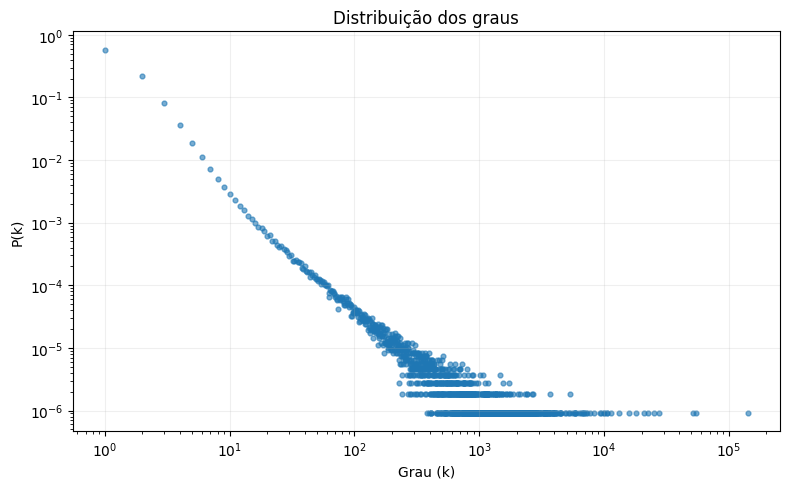

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(graus, P_k, s=12, alpha=0.6)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Grau (k)")
plt.ylabel("P(k)")
plt.title("Distribuição dos graus")
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig("distribuicao_graus_wikipedia.pdf", bbox_inches="tight")
plt.show()

#### Parte 8

In [ ]:
# 8. Calcular o número de componentes do grafo (no caso dos grafos
# não direcionados) e, se tiver mais de uma componente, plotar a
# distribuição dos tamanhos das componentes.

numero_componentes = nx.number_connected_components(G)
print("Número de componentes:", numero_componentes)

Número de componentes: 1076


In [ ]:
tamanhos = [len(c) for c in nx.connected_components(G)]

print("Número de componentes:", len(tamanhos))
print("Mayor componente:", max(tamanhos))
print("Menor componente:", min(tamanhos))

Número de componentes: 1076
Mayor componente: 1091742
Menor componente: 2


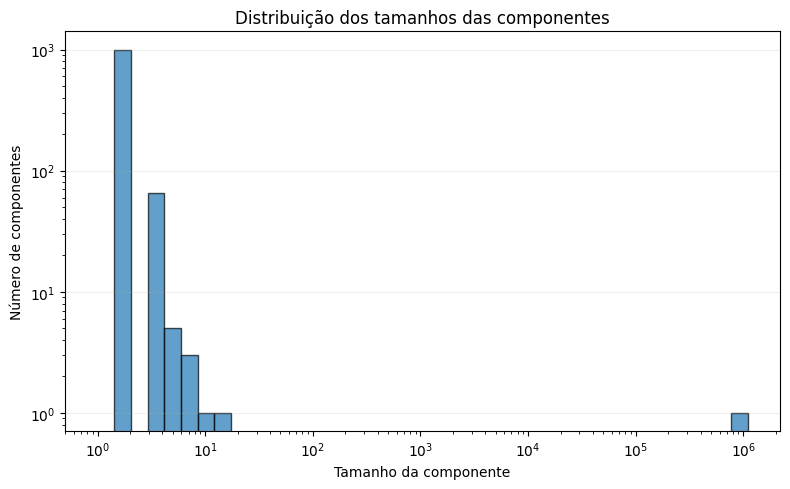

In [ ]:
# Bins logarítmicos
bins = np.logspace(0, np.log10(max(tamanhos)), 40)
plt.figure(figsize=(8, 5))

plt.hist(tamanhos, bins=bins, edgecolor="black", alpha=0.7)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Tamanho da componente")
plt.ylabel("Número de componentes")
plt.title("Distribuição dos tamanhos das componentes")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

#### Parte 9

Subgraph
Nodes: 128
Edges: 3872


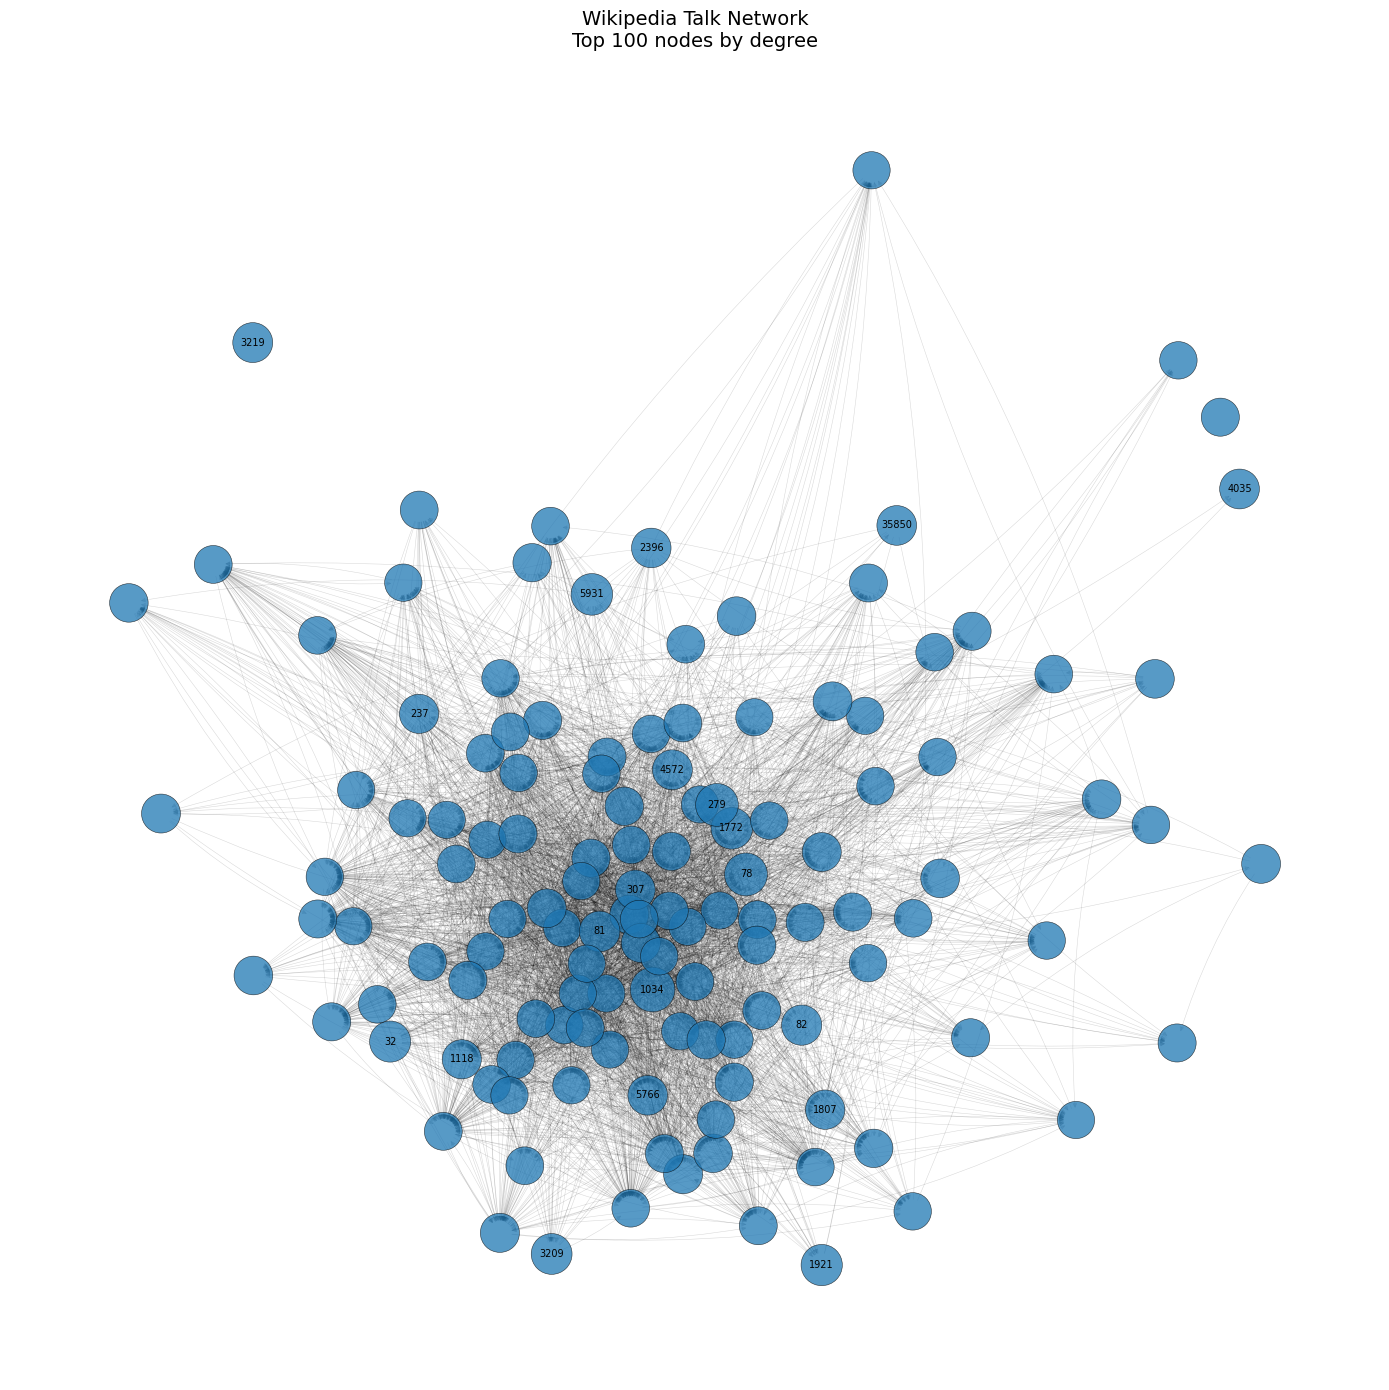

In [ ]:
# 9. De forma complementar e opcional, fazer uma visualização
# do grafo (pode ser entregue em arquivo separado).

N = 128
degree = dict(DG.degree())
top_nodes = sorted(degree, key=degree.get, reverse=True)[:N]

H = DG.subgraph(top_nodes).copy()

print("Subgraph")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

node_sizes = [80 + 80 * np.log1p(degree[node]) for node in H.nodes()]
pos = nx.spring_layout(H, seed=42, k=2.5, iterations=100)

plt.figure(figsize=(14, 14))
nx.draw_networkx_nodes(
    H, pos, node_size=node_sizes,
    alpha=0.75, linewidths=0.4, edgecolors="black"
)

nx.draw_networkx_edges(
    H, pos, arrows=True, arrowstyle="-|>", arrowsize=7,
    width=0.4, alpha=0.15, connectionstyle="arc3,rad=0.08"
)

top10 = set(top_nodes[:20])
labels = {node: node
    for node in H.nodes()
    if node in top10
}

nx.draw_networkx_labels(H, pos, labels=labels, font_size=7)
plt.title(
    "Wikipedia Talk Network\n"
    "Top 100 nodes by degree",
    fontsize=14
)

plt.axis("off")
plt.tight_layout()

# plt.savefig("wikipedia_talk_top100.png", dpi=300, bbox_inches="tight")
plt.show()